# India data for CatDSGE

What the project's loaders and the RBI workbooks say about India, where the two disagree, and the mixed-frequency quarterly panel built from them. Annual series sit on the last quarter of their year for the Kalman filter to read as a temporal aggregate.

In [1]:
import logging
import warnings

from itertools import pairwise
from pathlib import Path
from typing import NamedTuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import statsmodels.formula.api as smf

from kuznets.bis import BISReader
from matplotlib.ticker import StrMethodFormatter
from statsmodels.tsa.x13 import x13_arima_analysis

import climate_risk as cr

from climate_risk.data.fred import load_fred_data
from climate_risk.data.ilo import load_labour_income_share
from climate_risk.data.partner_activity import load_partner_activity
from climate_risk.data.pwt import load_pwt_data
from climate_risk.data.weo import load_government_debt
from climate_risk.plotting import PALETTE, configure_plot_style
from rbi_workbooks import (CURRENT_ACCOUNT_ITEMS,
                           fiscal_year_start,
                           load_all_india_cpi,
                           load_current_account,
                           load_monthly_trade,
                           load_quarterly_gdp,
                           sum_complete_years)

configure_plot_style(add_grid=True)
logging.getLogger("climate_risk").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", message="Workbook contains no default style")

cache_dir = Path.cwd().parents[1] / "data"
rbi_dir = Path("data/rbi")
output_dir = Path("data")

RUPEES_PER_CRORE = 1e7
DOLLARS_PER_MILLION = 1e6

## 1. Project loaders

In [2]:
india = pl.col("country_code") == "IND"

world_bank = cr.load_wb_data(cache_dir).filter(india)
pwt = load_pwt_data(cache_dir).filter(india)
labour_share = load_labour_income_share(cache_dir, ["IND"])
partner_activity = load_partner_activity(cache_dir,
                                         ["IND"],
                                         last_year=2023)
fred = load_fred_data(cache_dir).to_pandas()
government_debt = load_government_debt(cache_dir, ["IND"])

world_bank_annual = world_bank.to_pandas().set_index("year")
pwt_annual = pwt.to_pandas().set_index("year")
labour_share_annual = labour_share.to_pandas().set_index("year")
partner_activity_annual = partner_activity.to_pandas().set_index("year")
government_debt_annual = government_debt.to_pandas().set_index("year")

## 2. RBI workbooks

Tables exported from the Reserve Bank of India's Database on Indian Economy, stored under `notebooks/dsge/data/rbi`. The national accounts are NSO estimates republished by the RBI.

In [3]:
REPLACEMENT_CHARACTER = chr(0xFFFD)


def rbi_workbook(prefix):
    return next((rbi_dir / "Macro").glob(f"{prefix}*.xlsx"))


inventory = pd.DataFrame([{"folder": path.parent.name,
                           "workbook": path.stem.strip(),
                           "sheets": " | ".join(pd.ExcelFile(path).sheet_names).replace(REPLACEMENT_CHARACTER, "-"),
                           "MB": path.stat().st_size / 1e6}
                          for folder in ["Macro", "Banking"]
                          for path in sorted((rbi_dir / folder).glob("*.xlsx"))])
inventory.style.format({"MB": "{:.1f}"}).hide(axis="index")

folder,workbook,sheets,MB
Macro,"Consumer Price Index - Rural, Urban, Combined (State-Wise)",CPI - 2010=100 | CPI - 2012=100 | CPI - 2024=100,2.1
Macro,Exports of Major Commodities - US Dollar,Old Items | New Items,0.0
Macro,Exports of Select Commodities to Principal Countries - US Dollar,Old Items | New Items,0.1
Macro,Imports of Major Commodities - US Dollar,Old Items | New Items,0.0
Macro,Indias Foreign Trade - US Dollar,Report 1,0.0
Macro,Indias Overall Balance of Payments - Quarterly - US Dollar,1990-91 Q1 to 1999-00 Q4 | 2000-01 Q1 Onwards,0.2
Macro,Quarterly Estimates of Gross Domestic Product (At Constant Prices) New Series (Base _ 2022-23),NAS - 1999-2000 | NAS - 2004-05 | NAS - 2011-12 | NAS - 2022-23,0.0
Macro,RBIB Table No. 23 _ Index of Industrial Production (Base_ 2004-05=100 & 2011-12 & 2022-23),IIP-2011-12=100 | (Growth Rate (IIP-2011-12=100)) | IIP-2022-23=100 | (Growth Rate (IIP-2022-23=100)),0.1
Banking,Table VI.5_ Credit to Various Sectors by NBFCs,Report (i),0.0
Banking,"_Bank Credit of SCBs - Bank Group, Population Group, Occupation (Sector), District Wise - Annual",Data | Data(1) | Data(2) | Summary - Year Wise | Summary - Occupation Wise | Summary - State Wise | Summary - District Wise,144.5


## 3. Quarterly national accounts

Four base-year sheets, constant prices in rupees crore, Indian fiscal quarters (Q1 is April to June).

In [4]:
rbi_gdp = load_quarterly_gdp(rbi_workbook("Quarterly Estimates of Gross Domestic Product"))

rbi_gdp.reset_index().groupby("base")["date"].agg(["min", "max", "count"])

,min,max,count
base,,,
1999-2000,1996Q2,2009Q3,54
2004-05,2004Q2,2014Q3,42
2011-12,2011Q2,2025Q3,58
2022-23,2022Q2,2026Q1,16


In [5]:
expenditure_components = ["consumption",
                          "government",
                          "investment",
                          "inventories",
                          "valuables",
                          "exports",
                          "discrepancy"]
expenditure_sum = rbi_gdp[expenditure_components].sum(axis=1) - rbi_gdp["imports"]
identity_gap = (expenditure_sum / rbi_gdp["gdp"] - 1).abs().groupby("base").max()

identity_gap.rename("max |components / GDP - 1|").to_frame().style.format("{:.1e}")

,max |components / GDP - 1|
base,
1999-2000,4.7e-06
2004-05,1.7e-06
2011-12,7.7e-07
2022-23,1.8e-15


The discrepancy is the balancing item, so the expenditure identity holds to within 5e-6 in every base.

In [6]:
yoy_growth = 100 * rbi_gdp["gdp"].groupby("base").pct_change(4).unstack("base")


def overlap_row(older, newer):
    common = yoy_growth[[older, newer]].dropna().index
    return {"older base": older,
            "newer base": newer,
            "overlap": f"{common.min()} to {common.max()}",
            "older growth (%)": yoy_growth.loc[common, older].mean(),
            "newer growth (%)": yoy_growth.loc[common, newer].mean()}


overlap_growth = pd.DataFrame([overlap_row(older, newer) for older, newer in pairwise(yoy_growth.columns)])
overlap_growth.set_index(["older base", "newer base"]).style.format({"older growth (%)": "{:.2f}",
                                                                     "newer growth (%)": "{:.2f}"})

,,overlap,older growth (%),newer growth (%)
older base,newer base,,,
1999-2000,2004-05,2005Q2 to 2009Q3,8.31,7.88
2004-05,2011-12,2012Q2 to 2014Q3,5.07,6.44
2011-12,2022-23,2023Q2 to 2025Q3,7.88,7.24


Across the 2011-12 revision the new base runs 1.4 points a year faster than the old one over the same quarters.

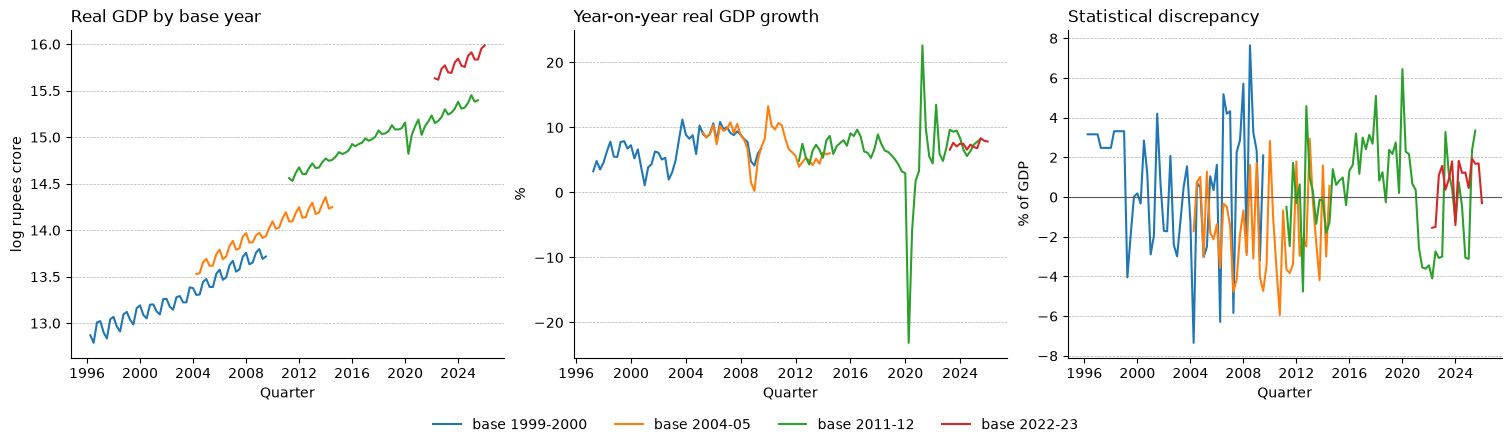

In [7]:
base_colors = dict(zip(yoy_growth.columns, plt.colormaps["tab10"].colors))

fig, ax = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for base, block in rbi_gdp.groupby("base"):
    quarters = block.index.get_level_values("date")
    dates = quarters.to_timestamp()
    ax[0].plot(dates,
               np.log(block["gdp"]),
               color=base_colors[base],
               label=f"base {base}")
    ax[1].plot(dates,
               yoy_growth.loc[quarters, base],
               color=base_colors[base])
    ax[2].plot(dates,
               100 * block["discrepancy"] / block["gdp"],
               color=base_colors[base])

ax[0].set_title("Real GDP by base year", loc="left")
ax[0].set(xlabel="Quarter", ylabel="log rupees crore")
ax[1].set_title("Year-on-year real GDP growth", loc="left")
ax[1].set(xlabel="Quarter", ylabel="%")
ax[2].set_title("Statistical discrepancy", loc="left")
ax[2].set(xlabel="Quarter", ylabel="% of GDP")
ax[2].axhline(0, color=PALETTE["divider"], lw=0.8)

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.1),
           ncol=len(labels),
           frameon=False)
plt.show()

The base years break in level by up to 0.5 log points, so any long series has to be spliced on growth rates. The statistical discrepancy swings between -7% and +8% of GDP before 2012. The quarterly national accounts are constant-price only and not seasonally adjusted.

In [8]:
latest_base = rbi_gdp.xs("2011-12", level="base")

rbi_calendar = sum_complete_years(latest_base,
                                  year=latest_base.index.year,
                                  periods_per_year=4)
rbi_fiscal = sum_complete_years(latest_base,
                                year=fiscal_year_start(latest_base.index),
                                periods_per_year=4)

world_bank_gdp_crore = world_bank_annual["real_gdp_lcu"] / RUPEES_PER_CRORE
alignment = pd.DataFrame({"calendar year": rbi_calendar["gdp"] / world_bank_gdp_crore,
                          "fiscal year, labeled by start": rbi_fiscal["gdp"] / world_bank_gdp_crore}).dropna()

(pd.concat({"2012-2022": alignment.loc[:2022].agg(["mean", "std"]).T,
            "2023-2024": alignment.loc[2023:].agg(["mean", "std"]).T},
           axis=1)
   .style.format("{:.4f}")
   .set_caption("RBI 2011-12 base real GDP / World Bank real_gdp_lcu"))

Summed over Indian fiscal years, the 2011-12 base is a constant 0.6189 of World Bank `real_gdp_lcu` through 2022. The two are one NSO series in different price bases, and the World Bank labels a fiscal year by the year it starts.

## 4. Coverage and expenditure shares

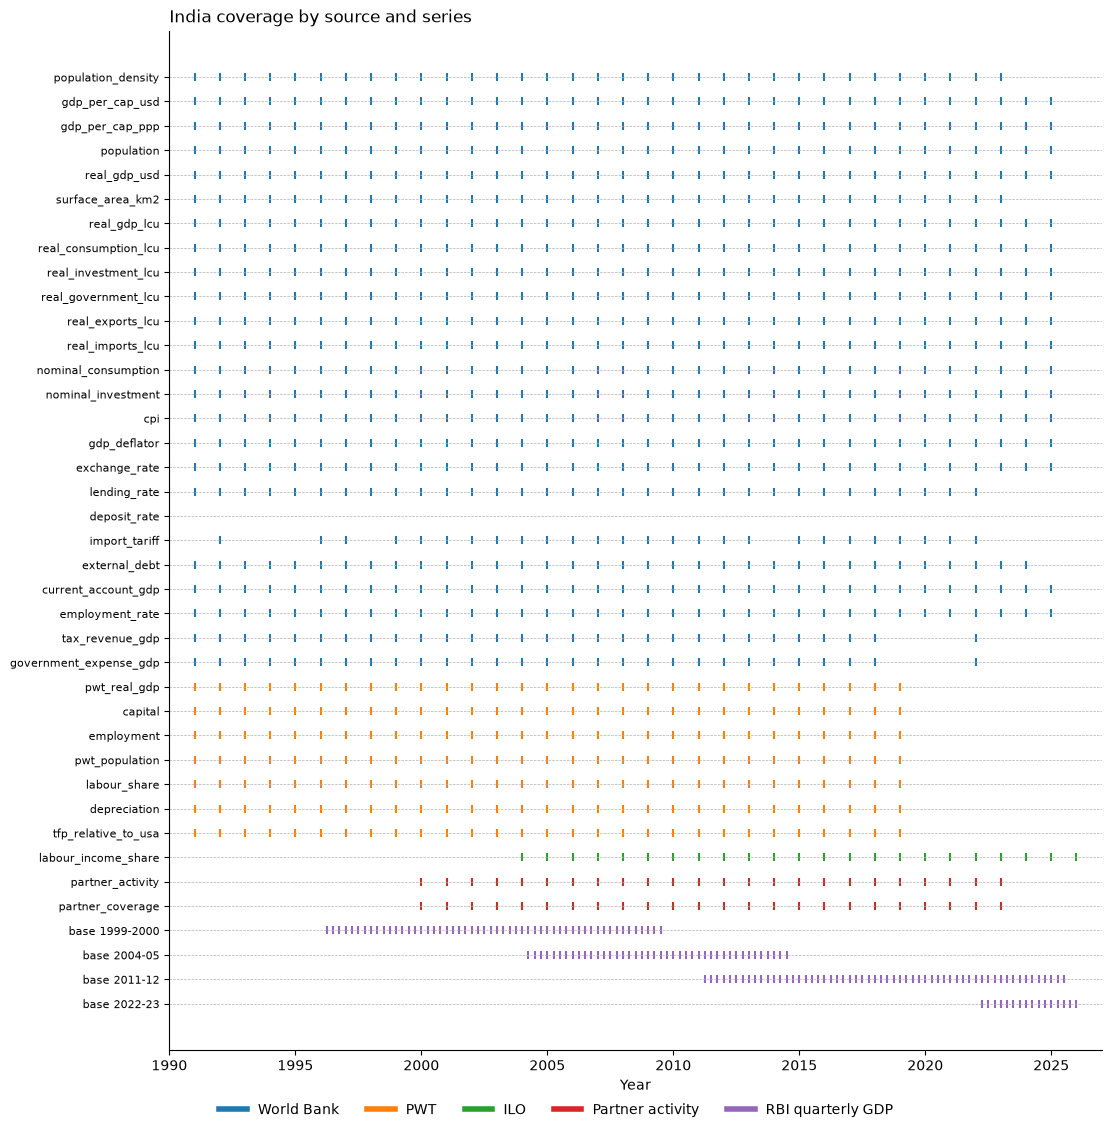

In [9]:
def available_years(frame):
    frame = frame.to_pandas().set_index("year").drop(columns=["country_code"], errors="ignore")
    return {column: frame.index[frame[column].notna()].to_numpy() for column in frame.columns}


def rbi_years(frame, base):
    block = frame.xs(base, level="base")
    return (block.index.year + (block.index.quarter - 1) / 4).to_numpy()


project_sources = {"World Bank": available_years(world_bank),
                   "PWT": available_years(pwt),
                   "ILO": available_years(labour_share),
                   "Partner activity": available_years(partner_activity),
                   "RBI quarterly GDP": {f"base {base}": rbi_years(rbi_gdp, base)
                                         for base in rbi_gdp.index.unique("base")}}
source_colors = dict(zip(project_sources, plt.colormaps["tab10"].colors))
coverage_rows = [(source, series, years)
                 for source, series_years in project_sources.items()
                 for series, years in series_years.items()]

fig, ax = plt.subplots(figsize=(11, 0.28 * len(coverage_rows)), layout="constrained")
for position, (source, _, years) in enumerate(coverage_rows):
    ax.scatter(years,
               np.full(len(years), position),
               marker="|",
               s=40,
               color=source_colors[source])

ax.set_yticks(range(len(coverage_rows)),
              labels=[series for _, series, _ in coverage_rows],
              fontsize=8)
ax.invert_yaxis()
ax.set_title("India coverage by source and series", loc="left")
ax.set(xlim=(1990, 2027), xlabel="Year")

legend_handles = [plt.Line2D([], [], color=color, lw=4, label=source) for source, color in source_colors.items()]
fig.legend(handles=legend_handles,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.03),
           ncol=len(legend_handles),
           frameon=False)
plt.show()

In [10]:
share_components = ["consumption", "investment", "government", "exports", "imports"]

rbi_real_shares = rbi_fiscal[share_components].div(rbi_fiscal["gdp"], axis=0)
world_bank_real_shares = (world_bank_annual[[f"real_{name}_lcu" for name in share_components]]
                          .div(world_bank_annual["real_gdp_lcu"], axis=0)
                          .set_axis(share_components, axis=1))

nominal_gdp = world_bank_annual["real_gdp_lcu"] * world_bank_annual["gdp_deflator"] / 100
world_bank_nominal_shares = pd.DataFrame({"consumption": world_bank_annual["nominal_consumption"] / nominal_gdp,
                                          "investment": world_bank_annual["nominal_investment"] / nominal_gdp})

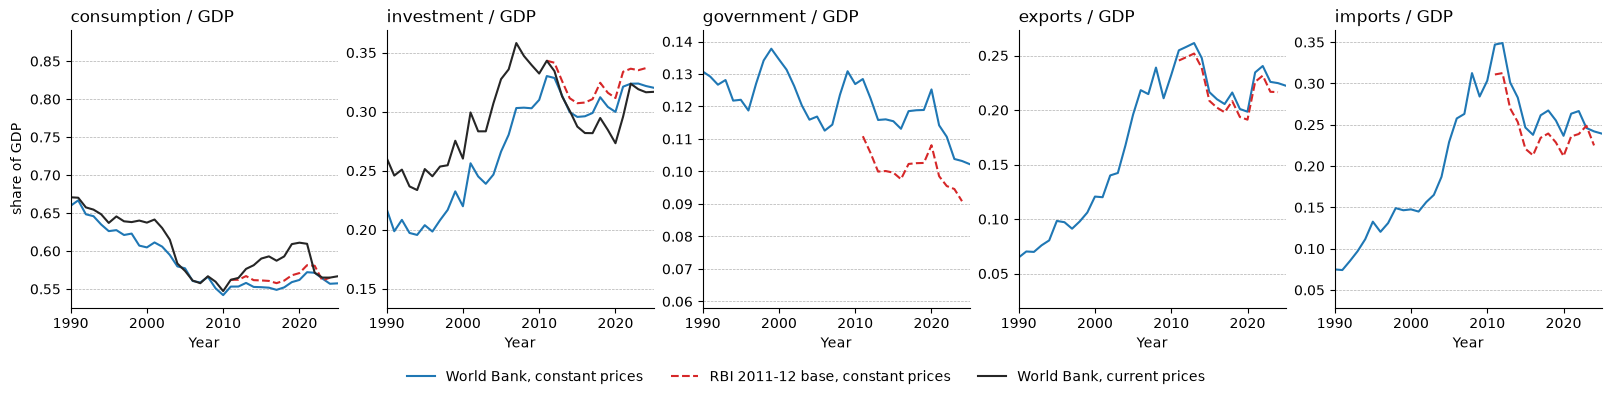

In [11]:
fig, ax = plt.subplots(1, 5, figsize=(16, 3.5), sharex=True, layout="constrained")
for axis, component in zip(ax, share_components, strict=True):
    axis.plot(world_bank_real_shares.index,
              world_bank_real_shares[component],
              color=PALETTE["primary"],
              label="World Bank, constant prices")
    axis.plot(rbi_real_shares.index,
              rbi_real_shares[component],
              color=PALETTE["secondary"],
              ls="--",
              label="RBI 2011-12 base, constant prices")
    if component in world_bank_nominal_shares:
        axis.plot(world_bank_nominal_shares.index,
                  world_bank_nominal_shares[component],
                  color=PALETTE["observed"],
                  label="World Bank, current prices")
    axis.set_title(f"{component} / GDP", loc="left")
    axis.set(xlim=(1990, 2025), xlabel="Year")
ax[0].set_ylabel("share of GDP")

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.12),
           ncol=len(labels),
           frameon=False)
plt.show()

Constant-price expenditure shares are not additive across sources. World Bank and RBI real shares differ by 2 to 3 points of GDP while total GDP matches exactly, so great ratios have to be nominal. The World Bank loader carries nominal consumption and investment only, at shares of 0.57 to 0.61 and 0.28 to 0.34 of GDP.

## 5. External accounts

Quarterly balance of payments, net flows in US dollars, summed to fiscal years and divided by nominal GDP in dollars rebuilt from the World Bank panel.

In [12]:
rbi_current_account = load_current_account(rbi_workbook("Indias Overall Balance of Payments"))

In [13]:
current_account_fiscal = sum_complete_years(rbi_current_account,
                                            year=fiscal_year_start(rbi_current_account.index),
                                            periods_per_year=4)

nominal_gdp_usd_millions = nominal_gdp / world_bank_annual["exchange_rate"] / DOLLARS_PER_MILLION
current_account_share = 100 * current_account_fiscal.div(nominal_gdp_usd_millions, axis=0).dropna()

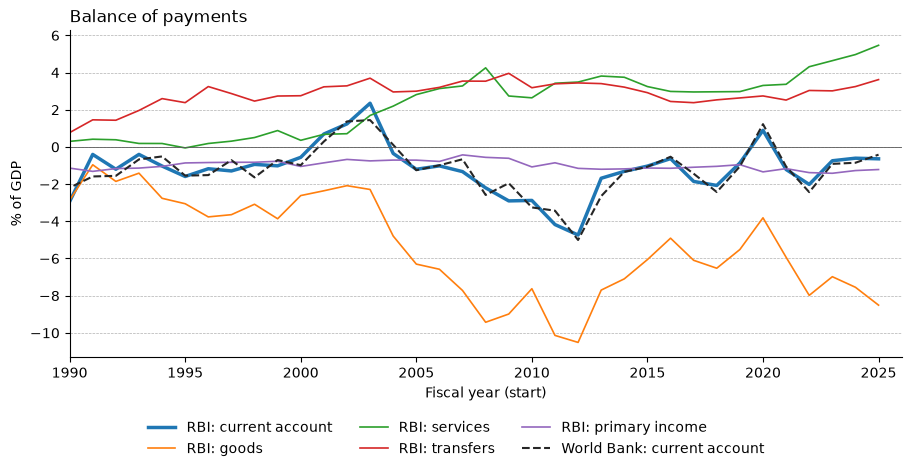

In [14]:
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
for item, color in zip(CURRENT_ACCOUNT_ITEMS.values(), plt.colormaps["tab10"].colors):
    ax.plot(current_account_share.index,
            current_account_share[item],
            color=color,
            lw=2.5 if item == "current account" else 1.2,
            label=f"RBI: {item}")
ax.plot(world_bank_annual.index,
        world_bank_annual["current_account_gdp"],
        color=PALETTE["observed"],
        ls="--",
        label="World Bank: current account")
ax.axhline(0, color=PALETTE["divider"], lw=0.6)

ax.set_title("Balance of payments", loc="left")
ax.set(xlim=(1990, 2026),
       xlabel="Fiscal year (start)",
       ylabel="% of GDP")

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.16),
           ncol=3,
           frameon=False)
plt.show()

The RBI current account reproduces World Bank `current_account_gdp`. The goods deficit runs at 6 to 10% of GDP and the services surplus at 3 to 5%. Primary income is about -1% of GDP, so India is a net foreign debtor, the opposite of the model's `phi_B > 0`.

### Customs trade against the balance of payments

Monthly customs trade summed to quarters against the balance-of-payments goods line.

In [15]:
monthly_trade = load_monthly_trade(rbi_workbook("Indias Foreign Trade"))

In [16]:
quarterly_trade = sum_complete_years(monthly_trade,
                                     year=monthly_trade.index.asfreq("Q"),
                                     periods_per_year=3)
trade_comparison = pd.DataFrame({"customs balance": quarterly_trade["balance"],
                                 "BoP goods balance": rbi_current_account["goods"],
                                 "customs turnover": quarterly_trade["exports"] + quarterly_trade["imports"]}).dropna()

balance_difference = trade_comparison["customs balance"] - trade_comparison["BoP goods balance"]
customs_gap = 100 * balance_difference / trade_comparison["customs turnover"]

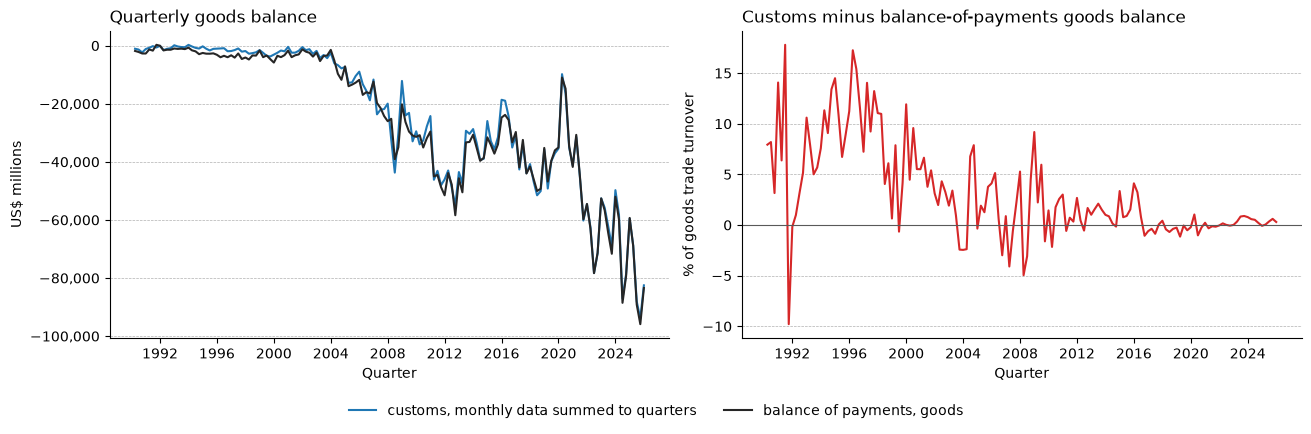

In [17]:
comparison_dates = trade_comparison.index.to_timestamp()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), layout="constrained")
ax[0].plot(comparison_dates,
           trade_comparison["customs balance"],
           color=PALETTE["primary"],
           label="customs, monthly data summed to quarters")
ax[0].plot(comparison_dates,
           trade_comparison["BoP goods balance"],
           color=PALETTE["observed"],
           label="balance of payments, goods")
ax[0].set_title("Quarterly goods balance", loc="left")
ax[0].set(xlabel="Quarter", ylabel="US$ millions")
ax[0].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax[1].plot(comparison_dates, customs_gap, color=PALETTE["secondary"])
ax[1].axhline(0, color=PALETTE["divider"], lw=0.8)
ax[1].set_title("Customs minus balance-of-payments goods balance", loc="left")
ax[1].set(xlabel="Quarter", ylabel="% of goods trade turnover")

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.12),
           ncol=len(labels),
           frameon=False)
plt.show()

The two goods balances differ by up to 18% of trade turnover in the 1990s and by at most 1.1% since 2017.

## 6. Prices

All-India combined CPI, general index, from each of the three bases. The 2024 base is a linked series back to 2013.

In [18]:
def summarize_cpi_base(block):
    months = block.index.get_level_values("month")
    reported = block["index"].notna()
    inflation_gap = (block["reported_inflation"] - block["computed_inflation"]).abs().max()
    return pd.Series({"first": months[reported].min(),
                      "last": months[reported].max(),
                      "months": reported.sum(),
                      "null months": ", ".join(str(month) for month in months[~reported]),
                      "max |reported - computed| inflation": inflation_gap})

The 2024-base sheet reports June and July 2026 at roughly twice the level of May, with a matching 109% year-on-year figure in the RBI table itself. `load_all_india_cpi` masks those two months, and they are the null months in the summary below.

In [19]:
rbi_cpi = load_all_india_cpi(rbi_workbook("Consumer Price Index"))

rbi_cpi.groupby("base").apply(summarize_cpi_base)

,first,last,months,null months,max |reported - computed| inflation
base,,,,,
2010,2011-01,2014-11,47,2014-12,0.01
2012,2013-01,2025-12,156,,0.00
2024,2013-01,2026-05,161,"2026-06, 2026-07",0.00


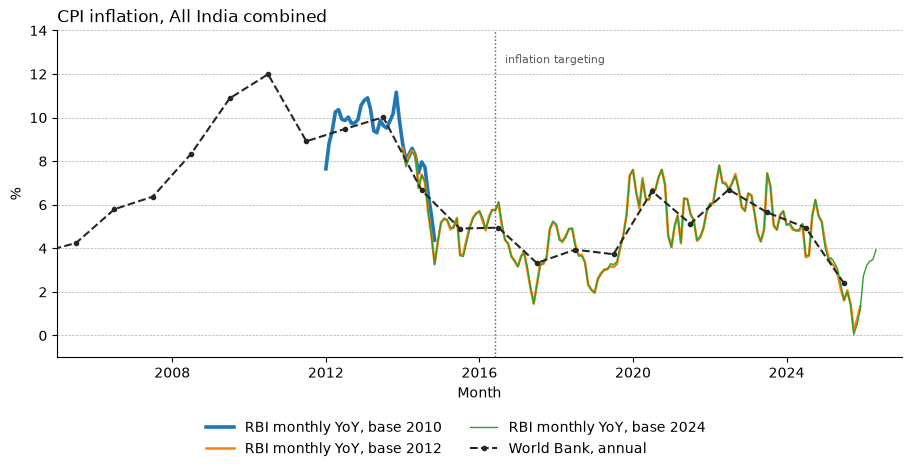

In [20]:
world_bank_inflation = 100 * world_bank_annual["cpi"].pct_change()
world_bank_inflation_dates = pd.to_datetime(world_bank_inflation.index.astype(str)) + pd.offsets.MonthEnd(6)

cpi_bases = rbi_cpi.index.unique("base")
cpi_base_colors = dict(zip(cpi_bases, plt.colormaps["tab10"].colors))
cpi_base_widths = dict(zip(cpi_bases, np.linspace(2.6, 1.0, len(cpi_bases))))

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
for base, block in rbi_cpi.groupby("base"):
    ax.plot(block.index.get_level_values("month").to_timestamp(),
            block["computed_inflation"],
            color=cpi_base_colors[base],
            lw=cpi_base_widths[base],
            label=f"RBI monthly YoY, base {base}")
ax.plot(world_bank_inflation_dates,
        world_bank_inflation,
        color=PALETTE["observed"],
        marker="o",
        ms=3,
        ls="--",
        label="World Bank, annual")

ax.axvline(pd.Timestamp("2016-06-01"), color=PALETTE["divider"], ls=":", lw=1)
ax.text(pd.Timestamp("2016-09-01"),
        12.5,
        "inflation targeting",
        fontsize=8,
        color=PALETTE["divider"])
ax.set_title("CPI inflation, All India combined", loc="left")
ax.set(xlim=(pd.Timestamp("2005-01-01"), pd.Timestamp("2026-12-31")),
       ylim=(-1, 14),
       xlabel="Month",
       ylabel="%")

handles, labels = ax.get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.16),
           ncol=2,
           frameon=False)
plt.show()

RBI CPI inflation reproduces World Bank `cpi` inflation. The linked 2024 base and the 2012 base agree to within 0.23 points of inflation over 2014 to 2025.

In [21]:
linked_inflation = rbi_cpi.xs("2024", level="base")["computed_inflation"]
inflation_windows = {"2014-2019": ("2014-01", "2019-12"),
                     "2016-2025 (targeting)": ("2016-06", "2025-12"),
                     "2022-2026": ("2022-01", "2026-05")}

mean_inflation = pd.Series({name: linked_inflation.loc[start:end].mean()
                            for name, (start, end) in inflation_windows.items()})
pd.DataFrame({"mean YoY inflation (%)": mean_inflation,
              "implied annual pi_bar": 1 + mean_inflation / 100}).style.format("{:.3f}")

,mean YoY inflation (%),implied annual pi_bar
2014-2019,4.593,1.046
2016-2025 (targeting),4.699,1.047
2022-2026,4.737,1.047


Trend inflation is 4.6 to 4.7% in every window since 2014, so `pi_bar` is about 1.047.

## 7. Spliced and seasonally adjusted national accounts

The four base-year sheets are spliced onto the 2011-12 base by quarter-on-quarter growth: older bases extend it backward, the 2022-23 base extends it forward. Each spliced series is then seasonally adjusted with X-13ARIMA-SEATS in logs.

In [22]:
NATIONAL_ACCOUNTS = ["gdp", "consumption", "investment", "government", "exports", "imports"]
ANCHOR_BASE = "2011-12"


def splice_on_growth(levels, anchor):
    """Extend the anchor column backward and forward with the other columns' growth rates, as far as they reach."""
    spliced = levels[anchor].copy()
    others = [column for column in levels.columns if column != anchor]

    def donor(date, neighbor, candidates):
        return next((column for column in candidates
                     if pd.notna(levels.at[date, column]) and pd.notna(levels.at[neighbor, column])), None)

    for date in reversed(levels.index[levels.index < spliced.first_valid_index()]):
        source = donor(date, date + 1, reversed(others))
        if source is None:
            break
        spliced[date] = spliced[date + 1] * levels.at[date, source] / levels.at[date + 1, source]

    for date in levels.index[levels.index > spliced.last_valid_index()]:
        source = donor(date, date - 1, others)
        if source is None:
            break
        spliced[date] = spliced[date - 1] * levels.at[date, source] / levels.at[date - 1, source]

    return spliced.dropna()


national_accounts_nsa = pd.DataFrame({component: splice_on_growth(rbi_gdp[component].unstack("base"),
                                                                  anchor=ANCHOR_BASE)
                                      for component in NATIONAL_ACCOUNTS})
national_accounts_nsa.index.name = "quarter"
national_accounts_nsa.agg(["first_valid_index", "last_valid_index", "count"]).T

,first_valid_index,last_valid_index,count
gdp,1996Q2,2026Q1,120
consumption,1996Q2,2026Q1,120
investment,1996Q2,2026Q1,120
government,1996Q2,2026Q1,120
exports,1996Q2,2026Q1,120
imports,1996Q2,2026Q1,120


In [23]:
def seasonally_adjust(series, log=True):
    """X-13ARIMA-SEATS seasonal adjustment with automatic outlier detection; additive when ``log`` is False.

    The x13as binary is found on PATH, or through the X13PATH environment variable.
    """
    observed = series.dropna()
    quarterly = observed.set_axis(observed.index.to_timestamp()).asfreq("QS")
    result = x13_arima_analysis(quarterly,
                                log=log,
                                outlier=True)
    return result.seasadj.set_axis(observed.index)


national_accounts_sa = national_accounts_nsa.apply(seasonally_adjust)

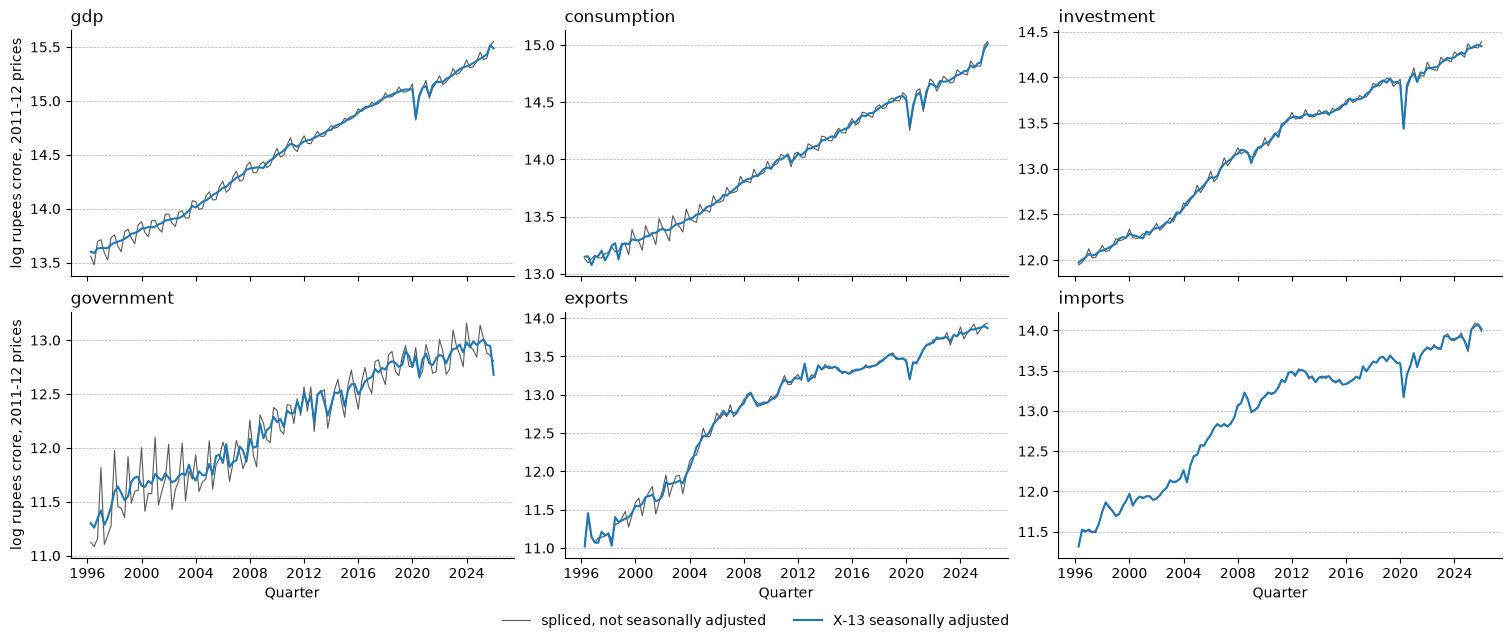

In [24]:
fig, ax = plt.subplots(2, 3, figsize=(15, 6), sharex=True, layout="constrained")
spliced_dates = national_accounts_nsa.index.to_timestamp()
for axis, component in zip(ax.flat, NATIONAL_ACCOUNTS, strict=True):
    axis.plot(spliced_dates,
              np.log(national_accounts_nsa[component]),
              color=PALETTE["divider"],
              lw=0.8,
              label="spliced, not seasonally adjusted")
    axis.plot(spliced_dates,
              np.log(national_accounts_sa[component]),
              color=PALETTE["primary"],
              label="X-13 seasonally adjusted")
    axis.set_title(component, loc="left")
for axis in ax[:, 0]:
    axis.set_ylabel("log rupees crore, 2011-12 prices")
for axis in ax[-1]:
    axis.set_xlabel("Quarter")

handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.06),
           ncol=len(labels),
           frameon=False)
plt.show()

## 8. Quarterly prices, current account and foreign series

CPI is the 2024-base linked series extended back with the 2010 base, averaged over complete quarters and seasonally adjusted. The current account is a quarterly sum in US dollars and changes sign, so it is adjusted additively. FRED's daily and monthly series and the BIS broad real effective exchange rate of the rupee are averaged over complete quarters, and US real GDP is quarterly as published. A rise in the BIS index is a real appreciation.

In [25]:
def complete_quarter_mean(monthly):
    """Average a monthly series over each calendar quarter that has all three months."""
    observed = monthly.dropna()
    grouped = observed.groupby(observed.index.asfreq("Q"))
    return grouped.mean().loc[grouped.size() == 3]


cpi_levels = rbi_cpi["index"].unstack("base").reindex(columns=["2010", "2012", "2024"])
cpi_monthly = splice_on_growth(cpi_levels, anchor="2024")
cpi_quarterly_sa = seasonally_adjust(complete_quarter_mean(cpi_monthly))

In [26]:
current_account_sa = seasonally_adjust(rbi_current_account["current account"], log=False)

In [27]:
QUARTERLY_FRED_SERIES = ["world_output"]

fred_monthly = (fred.assign(month=pd.PeriodIndex(fred["date"], freq="M"))
                    .groupby(["series", "month"])["value"].mean()
                    .unstack("series"))
foreign_quarterly = fred_monthly.drop(columns=QUARTERLY_FRED_SERIES).apply(complete_quarter_mean)
for name in QUARTERLY_FRED_SERIES:
    native = fred_monthly[name].dropna()
    foreign_quarterly[name] = native.set_axis(native.index.asfreq("Q"))

real_effective_exchange_rate_monthly = BISReader(dataflow="WS_EER",
                                                 selections={"FREQ": "M",
                                                             "EER_TYPE": "R",
                                                             "EER_BASKET": "B",
                                                             "REF_AREA": "IN"},
                                                 start="1996").read().iloc[:, 0]
real_effective_exchange_rate = complete_quarter_mean(
    real_effective_exchange_rate_monthly.set_axis(real_effective_exchange_rate_monthly.index.to_period("M")))

### Noise in the quarterly levels

Checks on the quarterly series the model observes, over the estimation window, 2012Q1 to 2024Q4 without the lockdown quarters. The national accounts and CPI are seasonally adjusted here and the BIS and FRED series are used as published, so an F-test on quarter-of-year dummies looks for seasonality left in any of them. The splice points show where a jump and reversal in growth could come from joining bases; the BIS and FRED series come from one source each and have none. The variance ratio $VR = \operatorname{Var}(\Delta_4 \log x) / (4 \operatorname{Var}(\Delta \log x))$ is 1 when quarterly growth is serially uncorrelated and 0.25 when growth is pure i.i.d. noise in the level. If growth is an uncorrelated signal plus noise in the level, the noise share of the variance of quarterly growth is $4(1 - VR)/3$. A positively autocorrelated signal, as a DSGE model implies, pushes VR above 1, so this share is a lower bound. The US 3-month rate is near zero for years at a time, so it enters in percentage-point changes. The permutation p-value is the share of 5000 permutations of the observed growth rates with a ratio at or below the data's.

In [28]:
ESTIMATION_WINDOW = pd.period_range("2012Q1", "2024Q4", freq="Q")
LOCKDOWN = pd.period_range("2020Q1", "2021Q4", freq="Q")
NOISE_CHECK_SERIES = {**{component: national_accounts_sa[component]
                         for component in ["gdp", "consumption", "investment", "exports", "imports"]},
                      "cpi": cpi_quarterly_sa,
                      "real_effective_exchange_rate": real_effective_exchange_rate,
                      **{name: foreign_quarterly[name] for name in ["world_rate_3m", "world_price_level", "commodity_all"]}}
# Near zero for years at a time, so its changes are taken in percentage points.
RATE_SERIES = ["world_rate_3m"]

anchor_levels = {component: rbi_gdp[component].unstack("base")[ANCHOR_BASE].dropna() for component in NATIONAL_ACCOUNTS}
splice_quarters = {**{component: [levels.index.min(), levels.index.max() + 1] for component, levels in anchor_levels.items()},
                   "cpi": [cpi_levels["2024"].first_valid_index().asfreq("Q")]}


def window_growth(name):
    levels = NOISE_CHECK_SERIES[name]
    change = levels.diff() if name in RATE_SERIES else 100 * np.log(levels).diff()
    change = change.reindex(ESTIMATION_WINDOW)
    return change.where(~change.index.isin(LOCKDOWN))


splice_rows = []
for name, quarters in splice_quarters.items():
    if name not in NOISE_CHECK_SERIES:
        continue
    growth = window_growth(name)
    for quarter in quarters:
        inside = quarter in ESTIMATION_WINDOW
        splice_rows.append({"series": name,
                            "splice quarter": str(quarter),
                            "inside window": inside,
                            "growth there (sd)": (growth[quarter] - growth.mean()) / growth.std() if inside else np.nan,
                            "growth after (sd)": ((growth[quarter + 1] - growth.mean()) / growth.std()
                                                  if inside and quarter + 1 in ESTIMATION_WINDOW else np.nan)})
pd.DataFrame(splice_rows).set_index(["series", "splice quarter"]).round(2)

inside window  growth there (sd)  \
series      splice quarter                                     
gdp         2011Q2                  False                NaN   
            2025Q4                  False                NaN   
consumption 2011Q2                  False                NaN   
            2025Q4                  False                NaN   
investment  2011Q2                  False                NaN   
            2025Q4                  False                NaN   
exports     2011Q2                  False                NaN   
            2025Q4                  False                NaN   
imports     2011Q2                  False                NaN   
            2025Q4                  False                NaN   
cpi         2013Q1                   True               1.78   

                            growth after (sd)  
series      splice quarter                     
gdp         2011Q2                        NaN  
            2025Q4                        NaN  
consumption 2011Q2                        NaN  
            2025Q4                        NaN  
investment  2011Q2                        NaN  
            2025Q4                        NaN  
exports     2011Q2                        NaN  
            2025Q4                        NaN  
imports     2011Q2                        NaN  
            2025Q4                        NaN  
cpi         2013Q1                       0.65

In [29]:
PERMUTATIONS = 5000
permutation_rng = np.random.default_rng(20261014)


def variance_ratio(growth):
    return growth.rolling(4).sum().var() / (4 * growth.var())


def permuted_variance_ratios(growth):
    observed = growth.notna().to_numpy()
    values = growth.to_numpy()[observed]
    shuffled = growth.copy()
    ratios = np.empty(PERMUTATIONS)
    for index in range(PERMUTATIONS):
        shuffled[observed] = permutation_rng.permutation(values)
        ratios[index] = variance_ratio(shuffled)
    return ratios


def seasonality_p_value(growth):
    """p-value of the F-test that quarter-of-year dummies explain nothing."""
    observed = growth.dropna()
    frame = pd.DataFrame({"growth": observed.to_numpy(), "quarter": observed.index.quarter.astype(str)})
    return smf.ols("growth ~ C(quarter)", data=frame).fit().f_pvalue


variance_ratio_rows = {}
for name in NOISE_CHECK_SERIES:
    growth = window_growth(name)
    ratio = variance_ratio(growth)
    variance_ratio_rows[name] = {"quarters": int(growth.notna().sum()),
                                 "seasonality p": seasonality_p_value(growth),
                                 "acf lag 1": growth.autocorr(lag=1),
                                 "variance ratio": ratio,
                                 "permutation p": (permuted_variance_ratios(growth) <= ratio).mean(),
                                 "implied noise share": float(np.clip(4 * (1 - ratio) / 3, 0, 1))}
pd.DataFrame(variance_ratio_rows).T.round(3)

,quarters,seasonality p,acf lag 1,variance ratio,permutation p,implied noise share
gdp,44.00,0.48,0.14,0.83,0.41,0.23
consumption,44.00,0.72,-0.48,0.28,0.00,0.96
investment,44.00,0.40,-0.20,0.80,0.35,0.27
exports,44.00,0.16,-0.43,0.31,0.00,0.93
imports,44.00,0.39,-0.30,0.74,0.28,0.34
cpi,44.00,0.96,0.28,1.94,1.00,0.00
real_effective_exchange_rate,44.00,0.46,0.05,1.16,0.79,0.00
world_rate_3m,44.00,0.98,0.81,2.52,1.00,0.00
world_price_level,44.00,0.93,0.64,1.75,0.99,0.00
commodity_all,44.00,0.68,0.36,1.55,0.97,0.00


No series shows seasonality left over, with every quarter-dummy p-value at 0.16 or above. The national accounts sit entirely inside the 2011-12 base over the window, so the only splice is CPI's in 2013Q1, and growth there shows no reversal. Consumption growth has a variance ratio of 0.28, close to the pure-noise floor of 0.25, so nearly all of its quarter-to-quarter variation is noise in the level. Export growth's 0.31 rests on 2012Q3 and 2012Q4, a 20% rise and a 21% fall in the national accounts that customs goods exports in dollars do not show. Without those two quarters its ratio is 0.82. Investment, imports, GDP and the real exchange rate are indistinguishable from uncorrelated growth. CPI inflation, the US rate and inflation, and commodity price growth are all persistent, with variance ratios of 1.5 to 2.5.

### Foreign series

The rest of the world enters the model through the US 3-month Treasury rate, US CPI inflation, the broad commodity price index relative to US CPI, the BIS real effective exchange rate of the rupee, and the export-weighted output of India's trading partners. The last is annual and observed as a deviation from a linear trend.

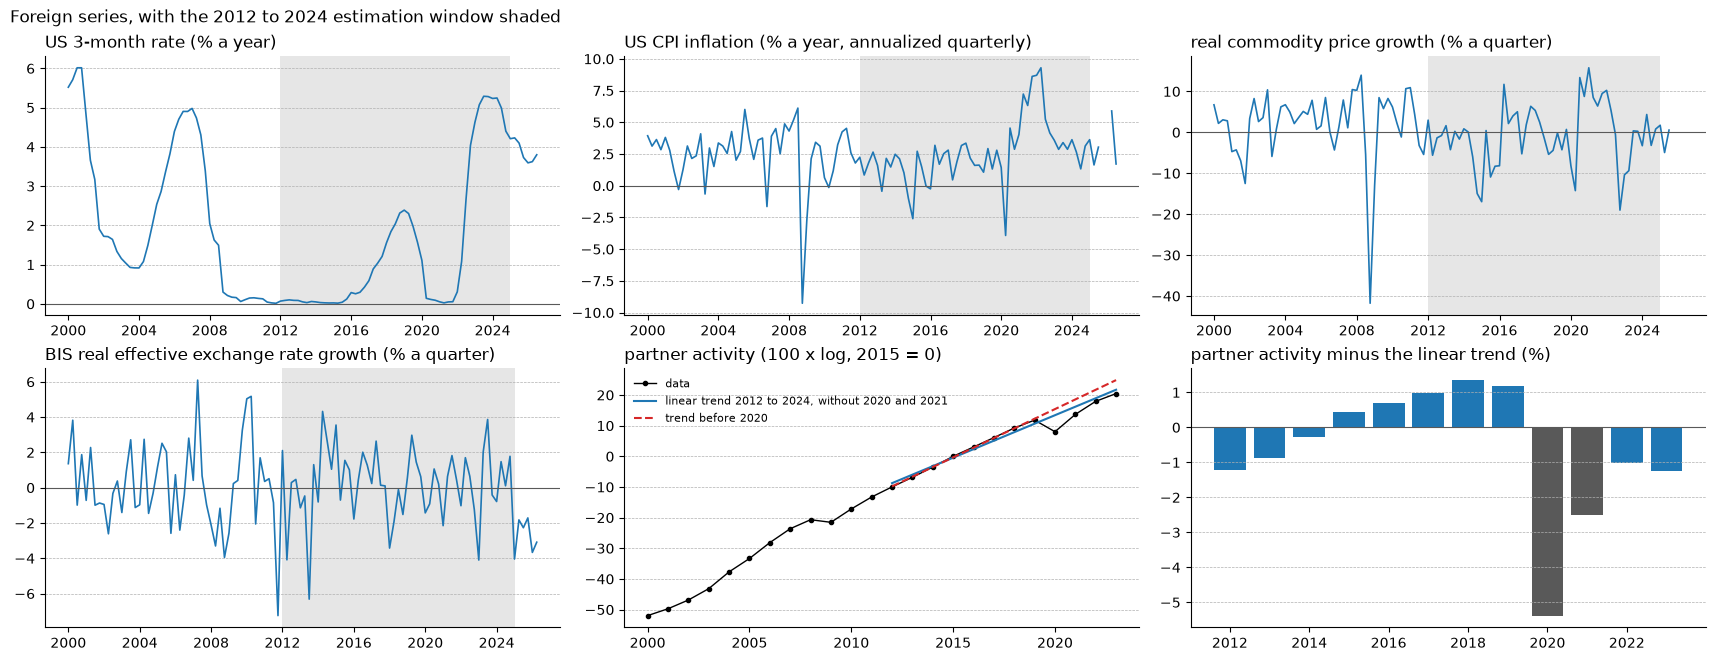

,annual growth (%),minus linear trend (%),minus pre-2020 trend (%)
year,,,
2012,3.29,-1.22,-0.18
2013,3.12,-0.87,-0.20
2014,3.35,-0.29,-0.00
2015,3.50,0.44,0.34
2016,3.04,0.70,0.23
2017,3.05,0.99,0.13
2018,3.13,1.35,0.12
2019,2.59,1.17,-0.44
2020,-3.78,-5.38,-7.37


In [30]:
PARTNER_TREND_YEARS = (2012, 2024)
PARTNER_BREAK_YEARS = [2020, 2021]

us_inflation = 400 * np.log(foreign_quarterly["world_price_level"]).diff()
real_commodity_growth = 100 * np.log(foreign_quarterly["commodity_all"]).diff() - us_inflation / 4
exchange_rate_growth = 100 * np.log(real_effective_exchange_rate).diff()

log_partner_activity = np.log(partner_activity_annual["partner_activity"])
trend_window = log_partner_activity.loc[PARTNER_TREND_YEARS[0]:PARTNER_TREND_YEARS[1]]
outside_break = ~trend_window.index.isin(PARTNER_BREAK_YEARS)
linear_trend = np.polyfit(trend_window.index[outside_break], trend_window[outside_break], deg=1)
before_break = trend_window.index < PARTNER_BREAK_YEARS[0]
pre_break_trend = np.polyfit(trend_window.index[before_break], trend_window[before_break], deg=1)

quarterly_panels = {"US 3-month rate (% a year)": foreign_quarterly["world_rate_3m"],
                    "US CPI inflation (% a year, annualized quarterly)": us_inflation,
                    "real commodity price growth (% a quarter)": real_commodity_growth,
                    "BIS real effective exchange rate growth (% a quarter)": exchange_rate_growth}

fig, axes = plt.subplots(nrows=2,
                         ncols=3,
                         figsize=(17, 6.5),
                         layout="constrained")
window_start, window_end = (ESTIMATION_WINDOW[0].to_timestamp(), ESTIMATION_WINDOW[-1].to_timestamp(how="end"))
for ax, (title, series) in zip(axes.flat, quarterly_panels.items()):
    series = series.loc["2000Q1":]
    ax.plot(series.index.to_timestamp(),
            series,
            color=PALETTE["primary"],
            lw=1.2)
    ax.axvspan(window_start, window_end, color=PALETTE["divider"], alpha=0.15, linewidth=0)
    ax.axhline(0.0, color=PALETTE["divider"], lw=0.8)
    ax.set_title(title, loc="left")

partner_years = log_partner_activity.loc[2000:].index
axes[1, 1].plot(partner_years,
                100 * log_partner_activity.loc[2000:],
                color="k",
                marker="o",
                markersize=3,
                lw=1.0,
                label="data")
axes[1, 1].plot(trend_window.index,
                100 * np.polyval(linear_trend, trend_window.index),
                color=PALETTE["primary"],
                lw=1.5,
                label=f"linear trend {PARTNER_TREND_YEARS[0]} to {PARTNER_TREND_YEARS[1]}, without 2020 and 2021")
axes[1, 1].plot(trend_window.index,
                100 * np.polyval(pre_break_trend, trend_window.index),
                color=PALETTE["secondary"],
                ls="--",
                lw=1.5,
                label="trend before 2020")
axes[1, 1].set_title("partner activity (100 x log, 2015 = 0)", loc="left")
axes[1, 1].legend(loc="upper left", frameon=False, fontsize=8)

axes[1, 2].bar(trend_window.index,
               100 * (trend_window - np.polyval(linear_trend, trend_window.index)),
               color=[PALETTE["divider"] if year in PARTNER_BREAK_YEARS else PALETTE["primary"]
                      for year in trend_window.index])
axes[1, 2].axhline(0.0, color=PALETTE["divider"], lw=0.8)
axes[1, 2].set_title("partner activity minus the linear trend (%)", loc="left")
fig.suptitle("Foreign series, with the 2012 to 2024 estimation window shaded", x=0.0, ha="left")
plt.show()

pd.DataFrame({"annual growth (%)": 100 * log_partner_activity.diff(),
              "minus linear trend (%)": 100 * (log_partner_activity - np.polyval(linear_trend, log_partner_activity.index)),
              "minus pre-2020 trend (%)": 100 * (log_partner_activity - np.polyval(pre_break_trend, log_partner_activity.index))}
             ).loc[PARTNER_TREND_YEARS[0]:PARTNER_TREND_YEARS[1]].round(2)

Partner activity grows 3.0 to 3.5% a year from 2012 to 2018 and ends 2022 and 2023 3.8% and 4.4% below its pre-2020 trend, a level loss that does not reverse. A single linear trend through both sides of that loss turns the steady growth before 2020 into a swing from -1.2% in 2012 to +1.35% in 2018, while against the trend before 2020 the same years deviate by less than 0.5%. The US 3-month rate sits at its lower bound through 2015 and again from 2020 to 2022, about half of the window.

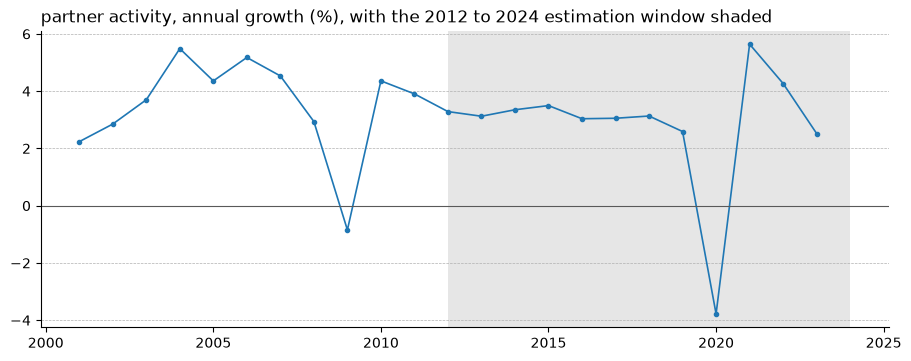

In [31]:
partner_growth = 100 * log_partner_activity.diff().loc[2001:]

fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
ax.plot(partner_growth.index,
        partner_growth,
        color=PALETTE["primary"],
        marker="o",
        markersize=3,
        lw=1.2)
ax.axvspan(PARTNER_TREND_YEARS[0], PARTNER_TREND_YEARS[1], color=PALETTE["divider"], alpha=0.15, linewidth=0)
ax.axhline(0.0, color=PALETTE["divider"], lw=0.8)
ax.set_title("partner activity, annual growth (%), with the 2012 to 2024 estimation window shaded", loc="left");

Partner growth has a visible cycle before the estimation window, above 5% in 2004 and 2006 and -0.9% in 2009. Inside the window it stays between 2.6% and 3.5% from 2012 to 2019, so apart from the 2020 fall and the recovery after it the series carries almost no variation.

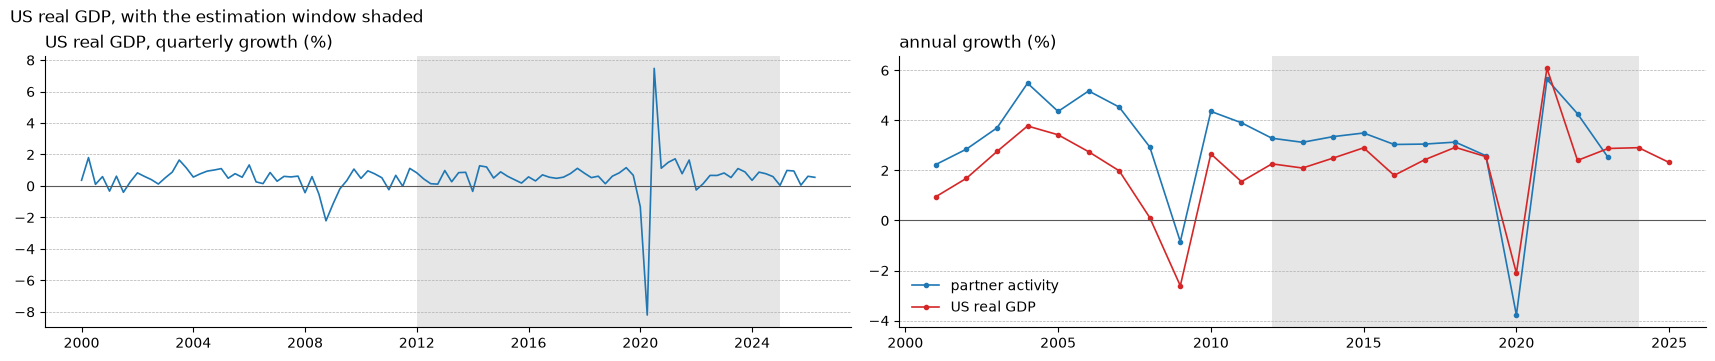

In [32]:
us_output_growth = 100 * np.log(foreign_quarterly["world_output"]).diff().loc["2000Q1":]
us_annual_output = np.log(foreign_quarterly["world_output"].groupby(foreign_quarterly.index.year).mean())

fig, axes = plt.subplots(ncols=2,
                         figsize=(17, 3.5),
                         layout="constrained")
axes[0].plot(us_output_growth.index.to_timestamp(),
             us_output_growth,
             color=PALETTE["primary"],
             lw=1.2)
axes[0].axvspan(window_start, window_end, color=PALETTE["divider"], alpha=0.15, linewidth=0)
axes[0].axhline(0.0, color=PALETTE["divider"], lw=0.8)
axes[0].set_title("US real GDP, quarterly growth (%)", loc="left")

axes[1].plot(partner_growth.index,
             partner_growth,
             color=PALETTE["primary"],
             marker="o",
             markersize=3,
             lw=1.2,
             label="partner activity")
axes[1].plot(us_annual_output.loc[2001:2025].index,
             100 * us_annual_output.diff().loc[2001:2025],
             color=PALETTE["secondary"],
             marker="o",
             markersize=3,
             lw=1.2,
             label="US real GDP")
axes[1].axvspan(PARTNER_TREND_YEARS[0], PARTNER_TREND_YEARS[1], color=PALETTE["divider"], alpha=0.15, linewidth=0)
axes[1].axhline(0.0, color=PALETTE["divider"], lw=0.8)
axes[1].set_title("annual growth (%)", loc="left")
axes[1].legend(loc="lower left", frameon=False)
fig.suptitle("US real GDP, with the estimation window shaded", x=0.0, ha="left");

US real GDP is quarterly, so it gives 44 observations over the window outside the lockdown quarters against 9 annual ones for partner activity. Its quarterly growth averages 0.61% with a standard deviation of 0.36 points and almost no autocorrelation. Annual US growth moves with partner growth across the whole sample, about a point lower, and like it is steady inside the window apart from 2020.

## 9. Annual series

Annual values sit on the last quarter of their year: Q4 for calendar years, Q1 of the next calendar year for Indian fiscal years (April to March). The World Bank national accounts and fiscal series follow the fiscal year, as the GDP alignment in section 3 shows. The IMF WEO's general government gross debt is also by fiscal year, dated by the year it starts in, and is a stock at the fiscal year's end in March. Annual series that repeat a quarterly RBI series are left out, and annual CPI inflation stops the year before quarterly CPI begins.

In [33]:
class AnnualSeries(NamedTuple):
    values: pd.Series
    source: str
    year_convention: str
    aggregation: str


annual_cpi_inflation = world_bank_annual["cpi"].pct_change().loc[:cpi_quarterly_sa.index.min().year - 1]

annual_series = {"nominal_consumption_share": AnnualSeries(values=world_bank_nominal_shares["consumption"],
                                                           source="World Bank",
                                                           year_convention="fiscal",
                                                           aggregation="ratio"),
                 "nominal_investment_share": AnnualSeries(values=world_bank_nominal_shares["investment"],
                                                          source="World Bank",
                                                          year_convention="fiscal",
                                                          aggregation="ratio"),
                 "tax_revenue_gdp": AnnualSeries(values=world_bank_annual["tax_revenue_gdp"] / 100,
                                                 source="World Bank",
                                                 year_convention="fiscal",
                                                 aggregation="ratio"),
                 "government_expense_gdp": AnnualSeries(values=world_bank_annual["government_expense_gdp"] / 100,
                                                        source="World Bank",
                                                        year_convention="fiscal",
                                                        aggregation="ratio"),
                 "government_debt": AnnualSeries(values=government_debt_annual["government_debt"],
                                                 source="IMF WEO",
                                                 year_convention="fiscal",
                                                 aggregation="end of period"),
                 "cpi_inflation_annual": AnnualSeries(values=annual_cpi_inflation,
                                                      source="World Bank",
                                                      year_convention="calendar",
                                                      aggregation="mean"),
                 "exchange_rate": AnnualSeries(values=world_bank_annual["exchange_rate"],
                                               source="World Bank",
                                               year_convention="calendar",
                                               aggregation="mean"),
                 "lending_rate": AnnualSeries(values=world_bank_annual["lending_rate"] / 100,
                                              source="World Bank",
                                              year_convention="calendar",
                                              aggregation="mean"),
                 "external_debt_usd": AnnualSeries(values=world_bank_annual["external_debt"],
                                                   source="World Bank",
                                                   year_convention="calendar",
                                                   aggregation="end of period"),
                 "employment_rate": AnnualSeries(values=world_bank_annual["employment_rate"] / 100,
                                                 source="World Bank",
                                                 year_convention="calendar",
                                                 aggregation="mean"),
                 "labour_share_pwt": AnnualSeries(values=pwt_annual["labour_share"],
                                                  source="PWT",
                                                  year_convention="calendar",
                                                  aggregation="ratio"),
                 "labour_share_ilo": AnnualSeries(values=labour_share_annual["labour_income_share"],
                                                  source="ILO",
                                                  year_convention="calendar",
                                                  aggregation="ratio"),
                 "partner_activity": AnnualSeries(values=partner_activity_annual["partner_activity"],
                                                  source="partner activity",
                                                  year_convention="calendar",
                                                  aggregation="mean")}

In [34]:
CLOSING_QUARTER = {"calendar": (0, 4), "fiscal": (1, 1)}


def place_annual(values, year_convention):
    """Move an annual series onto the last calendar quarter of the year it covers."""
    values = values.dropna()
    year_shift, quarter = CLOSING_QUARTER[year_convention]
    closing_quarters = pd.PeriodIndex([pd.Period(f"{int(year) + year_shift}Q{quarter}") for year in values.index])
    return values.set_axis(closing_quarters)


annual_placed = pd.DataFrame({name: place_annual(series.values, series.year_convention)
                              for name, series in annual_series.items()})
annual_placed.index.name = "quarter"
annual_placed.notna().sum().rename("annual observations").to_frame().T

,nominal_consumption_share,nominal_investment_share,tax_revenue_gdp,government_expense_gdp,government_debt,cpi_inflation_annual,exchange_rate,lending_rate,external_debt_usd,employment_rate,labour_share_pwt,labour_share_ilo,partner_activity
annual observations,66,66,46,46,36,50,66,45,55,35,70,23,24


## 10. The panel

One row per calendar quarter over the national-accounts window, one column per observable, with a metadata table recording each column's source, native frequency, units and how an annual value aggregates the quarters it covers.

In [35]:
QUARTERS_PER_YEAR = 4

quarterly_columns = {**{component: national_accounts_sa[component] for component in NATIONAL_ACCOUNTS},
                     "cpi": cpi_quarterly_sa,
                     "current_account_usd": current_account_sa,
                     "real_effective_exchange_rate": real_effective_exchange_rate,
                     **{name: foreign_quarterly[name] for name in foreign_quarterly.columns}}

sample = pd.period_range(national_accounts_sa.index.min(),
                         national_accounts_sa.index.max(),
                         freq="Q",
                         name="quarter")

year_starts_in_sample = (annual_placed.index - (QUARTERS_PER_YEAR - 1)) >= sample.min()
panel = (pd.concat([pd.DataFrame(quarterly_columns), annual_placed.loc[year_starts_in_sample]], axis=1)
           .reindex(sample))

In [36]:
METADATA_FIELDS = ["source", "native frequency", "units", "seasonal adjustment", "aggregation"]
NATIONAL_ACCOUNTS_METADATA = ("RBI", "quarterly", "rupees crore, 2011-12 prices", "X-13, log", "sum")
QUARTERLY_METADATA = {**dict.fromkeys(NATIONAL_ACCOUNTS, NATIONAL_ACCOUNTS_METADATA),
                      "cpi": ("RBI", "monthly", "index, 2024 = 100", "X-13, log", "mean"),
                      "current_account_usd": ("RBI", "quarterly", "US$ millions", "X-13, additive", "sum"),
                      "real_effective_exchange_rate": ("BIS", "monthly", "index, 2020 = 100", "none", "mean"),
                      "world_rate_3m": ("FRED", "daily", "percent per year", "none", "mean"),
                      "world_rate_10y": ("FRED", "daily", "percent per year", "none", "mean"),
                      "world_price_level": ("FRED", "monthly", "index, 1982-84 = 100", "source-adjusted", "mean"),
                      "world_output": ("FRED", "quarterly", "billions of chained 2017 US$, annual rate",
                                       "source-adjusted", "none"),
                      "commodity_all": ("FRED", "monthly", "index, 2016 = 100", "none", "mean"),
                      "commodity_energy": ("FRED", "monthly", "index, 2016 = 100", "none", "mean"),
                      "commodity_food": ("FRED", "monthly", "index, 2016 = 100", "none", "mean")}
ANNUAL_UNITS = {"exchange_rate": "rupees per US$",
                "external_debt_usd": "current US$",
                "partner_activity": "index, 2015 base"}

quarterly_metadata = (pd.DataFrame(QUARTERLY_METADATA, index=METADATA_FIELDS).T
                        .assign(**{"panel frequency": "quarterly", "year convention": "calendar"}))
annual_metadata = pd.DataFrame({name: {"source": series.source,
                                       "native frequency": "annual",
                                       "units": ANNUAL_UNITS.get(name, "fraction"),
                                       "seasonal adjustment": "none",
                                       "aggregation": series.aggregation,
                                       "panel frequency": "annual, last quarter of year",
                                       "year convention": series.year_convention}
                                for name, series in annual_series.items()}).T

metadata = pd.concat([quarterly_metadata, annual_metadata]).assign(first=panel.apply(pd.Series.first_valid_index),
                                                                    last=panel.apply(pd.Series.last_valid_index),
                                                                    observations=panel.notna().sum())
metadata.style.set_caption(f"Panel {sample.min()} to {sample.max()}, {len(sample)} quarters")

,source,native frequency,units,seasonal adjustment,aggregation,panel frequency,year convention,first,last,observations
gdp,RBI,quarterly,"rupees crore, 2011-12 prices","X-13, log",sum,quarterly,calendar,1996Q2,2026Q1,120
consumption,RBI,quarterly,"rupees crore, 2011-12 prices","X-13, log",sum,quarterly,calendar,1996Q2,2026Q1,120
investment,RBI,quarterly,"rupees crore, 2011-12 prices","X-13, log",sum,quarterly,calendar,1996Q2,2026Q1,120
government,RBI,quarterly,"rupees crore, 2011-12 prices","X-13, log",sum,quarterly,calendar,1996Q2,2026Q1,120
exports,RBI,quarterly,"rupees crore, 2011-12 prices","X-13, log",sum,quarterly,calendar,1996Q2,2026Q1,120
imports,RBI,quarterly,"rupees crore, 2011-12 prices","X-13, log",sum,quarterly,calendar,1996Q2,2026Q1,120
cpi,RBI,monthly,"index, 2024 = 100","X-13, log",mean,quarterly,calendar,2011Q1,2026Q1,61
current_account_usd,RBI,quarterly,US$ millions,"X-13, additive",sum,quarterly,calendar,1996Q2,2026Q1,120
real_effective_exchange_rate,BIS,monthly,"index, 2020 = 100",none,mean,quarterly,calendar,1996Q2,2026Q1,120
world_rate_3m,FRED,daily,percent per year,none,mean,quarterly,calendar,1996Q2,2026Q1,120


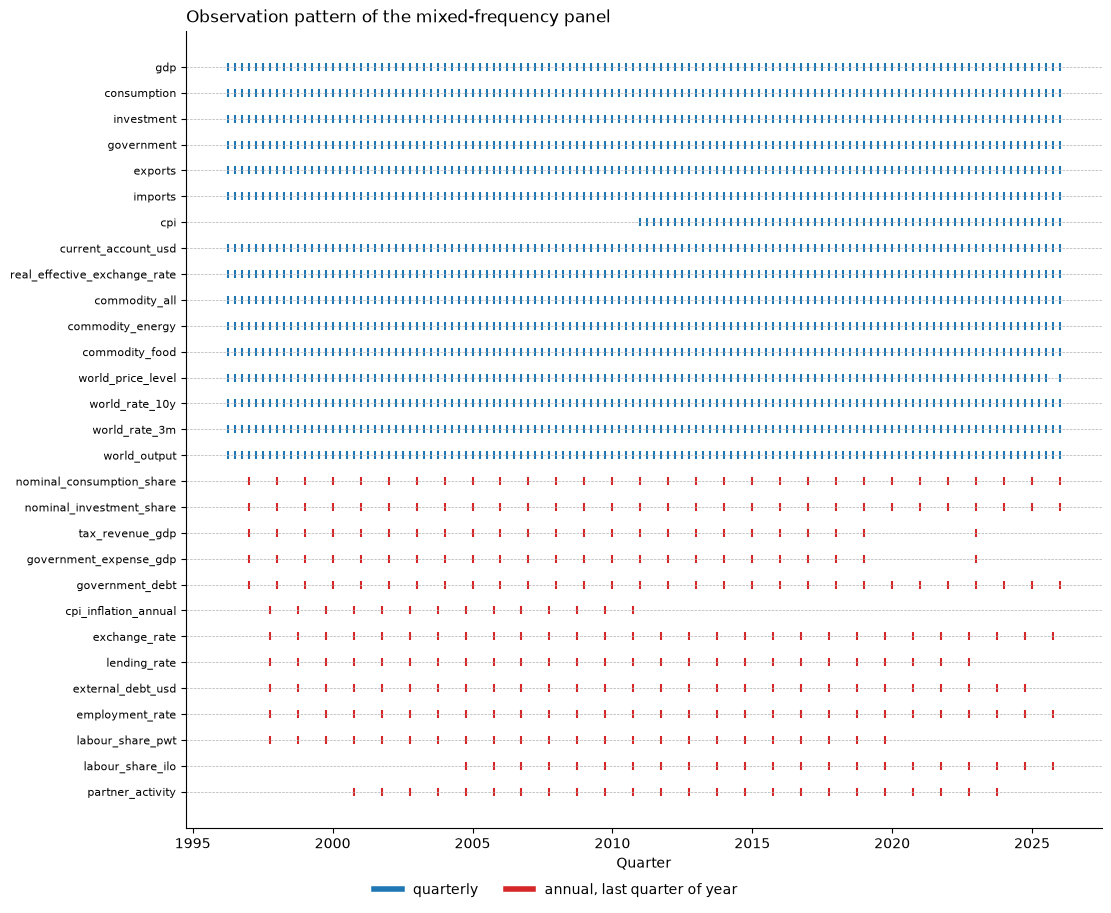

In [37]:
frequency_colors = {"quarterly": PALETTE["primary"], "annual, last quarter of year": PALETTE["secondary"]}
quarter_positions = panel.index.year + (panel.index.quarter - 1) / 4

fig, ax = plt.subplots(figsize=(11, 0.3 * len(panel.columns)), layout="constrained")
for position, column in enumerate(panel.columns):
    observed = panel[column].notna().to_numpy()
    ax.scatter(quarter_positions[observed],
               np.full(observed.sum(), position),
               marker="|",
               s=40,
               color=frequency_colors[metadata.at[column, "panel frequency"]])

ax.set_yticks(range(len(panel.columns)),
              labels=panel.columns,
              fontsize=8)
ax.invert_yaxis()
ax.set_title("Observation pattern of the mixed-frequency panel", loc="left")
ax.set(xlabel="Quarter")

legend_handles = [plt.Line2D([], [], color=color, lw=4, label=label) for label, color in frequency_colors.items()]
fig.legend(handles=legend_handles,
           loc="lower center",
           bbox_to_anchor=(0.5, -0.04),
           ncol=len(legend_handles),
           frameon=False)
plt.show()

In [38]:
panel_by_date = panel.set_axis(panel.index.to_timestamp(how="start")).rename_axis("quarter_start")
panel_by_date.to_parquet(output_dir / "india_mixed_frequency.parquet")
metadata.rename_axis("column").to_csv(output_dir / "india_mixed_frequency_metadata.csv")

sorted(path.name for path in output_dir.glob("india_mixed_frequency*"))

['india_mixed_frequency.parquet', 'india_mixed_frequency_metadata.csv']